# Notebook 03 — Contrôler un enregistrement de capteur

**Objectif :** charger un CSV d'accélération, vérifier sa qualité **avant** de le tracer, trouver les défauts et décider quoi en faire.

**Fichier :** `../data/sample_acceleration.csv`. Il est **simulé** (voir `make_sample_data.py`), dans le même format que les enregistrements du TP01 : `seq,t_us,ax_g,ay_g,az_g`. Deux défauts y ont été cachés volontairement.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/sample_acceleration.csv")
OUT = Path("../output")          # dossier de sortie (ignoré par git)
OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
df.head()

,seq,t_us,ax_g,ay_g,az_g
0,0,0,0.17609,0.00838,1.01269
1,1,8801,0.18729,0.00942,1.01352
2,2,17551,0.19814,0.01162,1.01069
3,3,26111,0.20600,0.00997,1.00838
4,4,34317,0.20787,0.01041,1.01170


## 1. Colonnes, types, dimensions, valeurs manquantes

In [2]:
print("dimensions :", df.shape)
print(df.dtypes)
print("valeurs manquantes par colonne :")
print(df.isna().sum())
assert list(df.columns) == ["seq", "t_us", "ax_g", "ay_g", "az_g"]

dimensions : (1139, 5)
seq       int64
t_us      int64
ax_g    float64
ay_g    float64
az_g    float64
dtype: object
valeurs manquantes par colonne :
seq     0
t_us    0
ax_g    0
ay_g    0
az_g    0
dtype: int64


## 2. La cadence réelle

`t_us` est l'instant de chaque mesure en microsecondes. Les intervalles entre mesures donnent la cadence.

In [3]:
dt = np.diff(df.t_us.to_numpy())
print("intervalle médian :", np.median(dt), "µs")
fs = (len(df) - 1) / ((df.t_us.iloc[-1] - df.t_us.iloc[0]) * 1e-6)
print(f"cadence mesurée : {fs:.2f} Hz")

intervalle médian : 8768.5 µs
cadence mesurée : 113.85 Hz


## 3. Tracer les trois axes

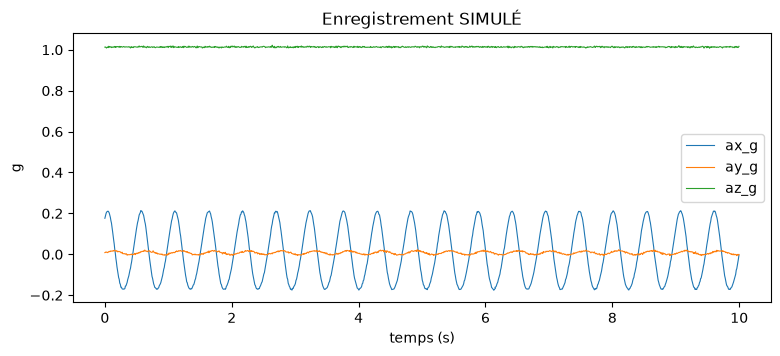

In [4]:
t = df.t_us * 1e-6
fig, ax = plt.subplots(figsize=(9, 3.5))
for col in ("ax_g", "ay_g", "az_g"):
    ax.plot(t, df[col], lw=0.8, label=col)
ax.set_xlabel("temps (s)"); ax.set_ylabel("g"); ax.legend()
ax.set_title("Enregistrement SIMULÉ")
fig.savefig(OUT / "signal.png", dpi=110, bbox_inches="tight")
plt.show()

La figure semble parfaite. **Elle ne suffit pourtant pas à valider le fichier** : les deux défauts sont invisibles à cette échelle.

## 4. Exercice : trouver les défauts

Écrivez du code qui répond à ces deux questions :
1. Y a-t-il des `seq` manquants ou en double ? (indice : `np.diff(df.seq)` doit valoir 1 partout)
2. Y a-t-il des `t_us` qui ne croissent pas ? (indice : `np.diff(df.t_us)` doit être > 0 partout)

Affichez les lignes concernées. La solution est dans `../solutions/`.

In [5]:
# À vous : écrivez votre code ici.

## 5. Décider : corriger, exclure ou garder ?

On ne « répare » pas une mesure perdue en inventant une valeur. Le cours applique une règle simple : **une fenêtre d'analyse qui contient un défaut est exclue**, et le reste de l'enregistrement est conservé. Ce choix est écrit noir sur blanc, avec sa justification.

La cellule suivante marque les lignes situées autour d'un défaut, puis exporte un CSV « nettoyé » qui ne garde que la plus longue portion sans défaut.

In [6]:
dseq = np.diff(df.seq.to_numpy())
dtu = np.diff(df.t_us.to_numpy())
mauvais = np.flatnonzero((dseq != 1) | (dtu <= 0))   # indice i : problème entre i et i+1
print("défauts entre les lignes :", [(int(i), int(i) + 1) for i in mauvais])
coupures = np.concatenate([[-1], mauvais, [len(df) - 1]])
morceaux = [(a + 1, b + 1) for a, b in zip(coupures[:-1], coupures[1:])]
debut, fin = max(morceaux, key=lambda m: m[1] - m[0])
propre = df.iloc[debut:fin]
print(f"plus longue portion sans défaut : lignes {debut} à {fin - 1} ({len(propre)} mesures)")
propre.to_csv(OUT / "sample_acceleration_clean.csv", index=False)
print("écrit :", OUT / "sample_acceleration_clean.csv")

défauts entre les lignes : [(399, 400), (699, 700)]
plus longue portion sans défaut : lignes 700 à 1138 (439 mesures)
écrit : ../output/sample_acceleration_clean.csv


## 6. Moyenne, écart-type et RMS par axe (portion propre)

In [7]:
stats = pd.DataFrame({
    "moyenne_g": propre[["ax_g", "ay_g", "az_g"]].mean(),
    "ecart_type_g": propre[["ax_g", "ay_g", "az_g"]].std(),
    "rms_g": np.sqrt((propre[["ax_g", "ay_g", "az_g"]] ** 2).mean()),
})
stats.round(4)

,moyenne_g,ecart_type_g,rms_g
ax_g,0.0027,0.1341,0.1340
ay_g,0.0072,0.0070,0.0100
az_g,1.0134,0.0019,1.0134


> **Questions.**
> 1. Pourquoi la RMS de `az_g` est-elle proche de 1 g alors que son écart-type est petit ?
> 2. Pourquoi la figure ne suffit-elle pas à valider la qualité d'un CSV ?
> 3. Pourquoi utiliser un environnement virtuel (`.venv`) plutôt que le Python du système ?

**Avant de rendre votre travail :** menu **Kernel → Restart Kernel and Run All Cells**. Si une cellule échoue, c'est qu'elle dépendait d'une cellule exécutée dans le désordre.